In [10]:
%pylab inline

import numpy as np
import pandas as pd
import re
import matplotlib
import matplotlib.image as mpimg
import seaborn as sns
import matplotlib.pyplot as plt
from operator import truediv
from math import log
import math
import time
import itertools
from collections import Counter
import random
import scipy.stats as stats


%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


C:\Users\C837471923\AppData\Local\anaconda3\envs\flowcyto_env\lib\site-packages\IPython\core\magics\pylab.py:162: UserWarning: pylab import has clobbered these variables: ['log', 'random']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the boxplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:675: UserWarning: Using the boxplot function without specifying `hue_order` is likely to produce an incorrect plot.
  warnings.warn(warning)


0.12801692353964803
0.06803223720342098


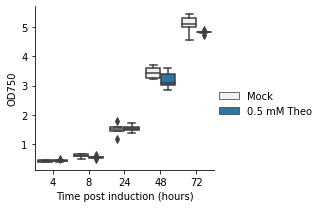

In [9]:

data = pd.io.excel.read_excel("Data_1a.xlsx")

fig = sns.FacetGrid(data=data,aspect=1.1)
fig = fig.map(sns.boxplot,'Time post induction (hours)','OD750','Treatment').add_legend()
fig.savefig('Fig1A.svg')
t_stat, p_value = stats.ttest_ind(data[(data['Time post induction (hours)']==48)&(data['Treatment']=='Mock')]['OD750'], data[(data['Time post induction (hours)']==48)&(data['Treatment']=='0.5 mM Theo')]['OD750'])
print(p_value)
t_stat, p_value = stats.ttest_ind(data[(data['Time post induction (hours)']==72)&(data['Treatment']=='Mock')]['OD750'], data[(data['Time post induction (hours)']==72)&(data['Treatment']=='0.5 mM Theo')]['OD750'])
print(p_value)

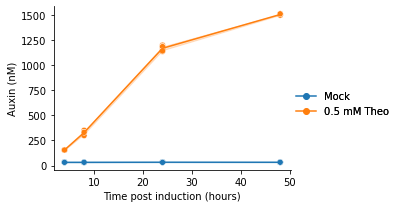

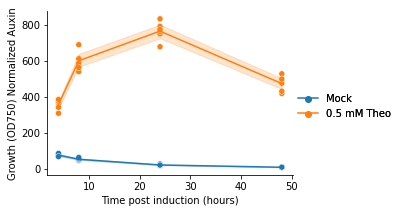

In [10]:
data = pd.io.excel.read_excel("Data_1bc.xlsx")

fig = sns.FacetGrid(data=data)
fig = fig.map(sns.scatterplot,'Time post induction (hours)','Auxin (nM)','Treatment').add_legend()
fig = fig.map(sns.lineplot,'Time post induction (hours)','Auxin (nM)','Treatment').add_legend()
fig.savefig('Fig1B.svg')


data['Growth (OD750) Normalized Auxin'] =  [x/y for (x,y) in zip(data['Auxin (nM)'],data['OD750'])]


fig = sns.FacetGrid(data=data)
fig = fig.map(sns.scatterplot,'Time post induction (hours)','Growth (OD750) Normalized Auxin','Treatment').add_legend()
fig = fig.map(sns.lineplot,'Time post induction (hours)','Growth (OD750) Normalized Auxin','Treatment').add_legend()
fig.savefig('Fig1C.svg')

C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the swarmplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:675: UserWarning: Using the swarmplot function without specifying `hue_order` is likely to produce an incorrect plot.
  warnings.warn(warning)


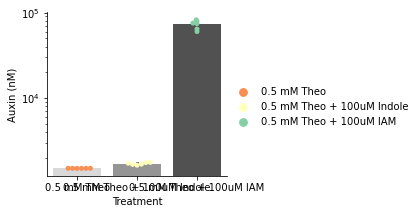

In [11]:
data = pd.io.excel.read_excel("Data_1D.xlsx")

fig = sns.FacetGrid(data=data,aspect=1.3)
fig = fig.map(sns.barplot,'Treatment','Auxin (nM)',palette='Greys').add_legend()
fig = fig.map(sns.swarmplot,'Treatment','Auxin (nM)','Treatment',palette='Spectral').add_legend()
plt.yscale('log')
fig.savefig('Fig1D.svg')



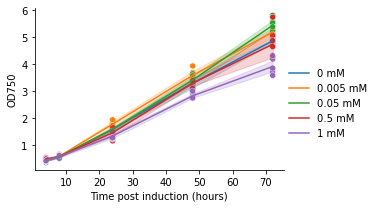

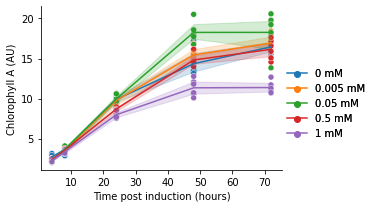

In [2]:
data = pd.io.excel.read_excel("Data_2A_sup1.xlsx")

fig = sns.FacetGrid(data=data,aspect=1.4)
fig = fig.map(sns.scatterplot,'Time post induction (hours)','OD750','Theo')
fig = fig.map(sns.lineplot,'Time post induction (hours)','OD750','Theo').add_legend()
fig.savefig('Fig2A.svg')


fig = sns.FacetGrid(data=data)
fig = fig.map(sns.scatterplot,'Time post induction (hours)','chla','Theo').add_legend()
fig = fig.map(sns.lineplot,'Time post induction (hours)','chla','Theo').add_legend()
plt.ylabel('Chlorophyll A (AU)')
fig.savefig('SuppFig2A.svg')



0.8243352069495378


C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


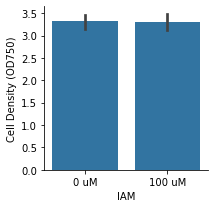

In [3]:
data = pd.io.excel.read_excel("Data_sup2.xlsx")


fig = sns.FacetGrid(data=data)
fig = fig.map(sns.barplot,'IAM','OD750').add_legend()
plt.ylabel('Cell Density (OD750)')

fig.savefig('SuppFig2B.svg')
t_stat, p_value = stats.ttest_ind(data[(data['IAM']=='0 uM')]['OD750'], data[(data['IAM']=='100 uM')]['OD750'])
print(p_value)


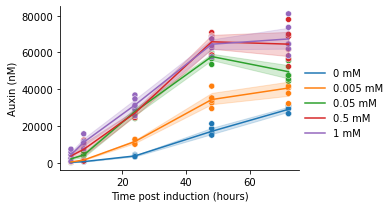

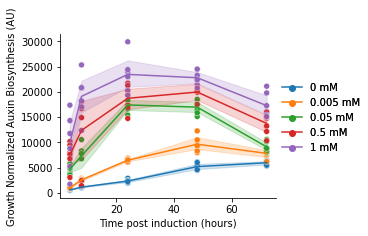

In [4]:
data = pd.io.excel.read_excel("Data_2b_sup4.xlsx")


fig = sns.FacetGrid(data=data,aspect=1.5)
fig = fig.map(sns.scatterplot,'Time post induction (hours)','Auxin (nM)','Theo')
fig = fig.map(sns.lineplot,'Time post induction (hours)','Auxin (nM)','Theo').add_legend()
fig.savefig('Fig2B.svg')

data['Growth (OD750) Normalized Auxin'] =  [x/y for (x,y) in zip(data['Auxin (nM)'],data['OD750'])]

fig = sns.FacetGrid(data=data)
fig = fig.map(sns.scatterplot,'Time post induction (hours)','Growth (OD750) Normalized Auxin','Theo').add_legend()
fig = fig.map(sns.lineplot,'Time post induction (hours)','Growth (OD750) Normalized Auxin','Theo').add_legend()
plt.ylabel("Growth Normalized Auxin Biosynthesis (AU)")
fig.savefig('SuppFig2D.svg')


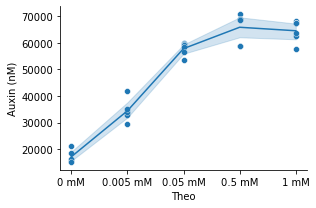

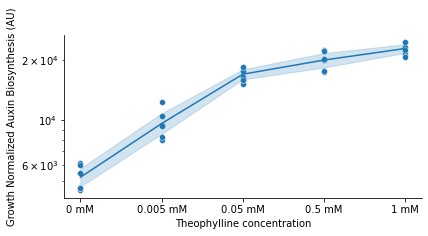

In [5]:
data = pd.io.excel.read_excel("Data_2c_sup3.xlsx")

fig = sns.FacetGrid(data=data,aspect=1.5)
fig = fig.map(sns.scatterplot,'Theo','Auxin (nM)')
fig = fig.map(sns.lineplot,'Theo','Auxin (nM)')
fig.savefig('Fig2C.svg')

fig = sns.FacetGrid(data=data,aspect=2)
fig = fig.map(sns.scatterplot,'Theo','Growth (OD750) Normalized Auxin')
fig = fig.map(sns.lineplot,'Theo','Growth (OD750) Normalized Auxin')
plt.yscale('log')
plt.ylabel("Growth Normalized Auxin Biosynthesis (AU)")
plt.xlabel("Theophylline concentration")
fig.savefig('SuppFig2C.svg')


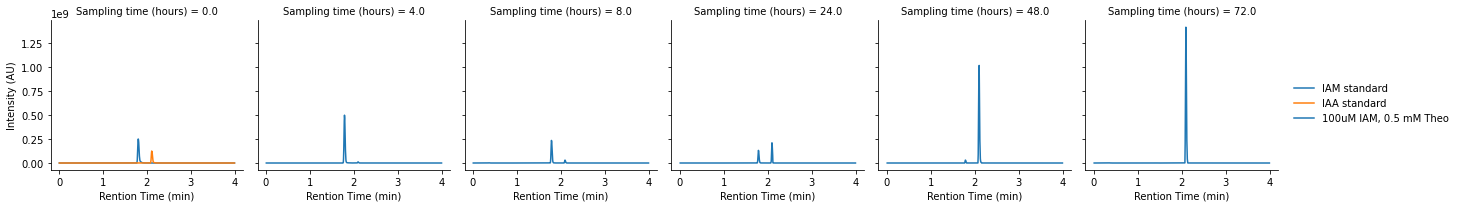

In [8]:
data = pd.io.excel.read_excel("Data_2e.xlsx")

fig = sns.FacetGrid(data=data,col='Sampling time (hours)', sharex=True, sharey=True)
fig = fig.map(sns.lineplot,'Rention Time (min)','Intensity (AU)','Treatment').add_legend()
fig.savefig('Fig2E.svg')


C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the swarmplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


29087.442174093885
67372.06668964465
Fold change:2.316190825113119
21.803330717661353
67372.06668964465
Fold change:3089.9896700218947


C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the swarmplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


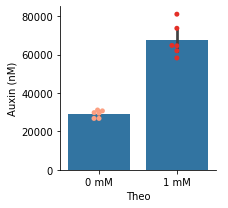

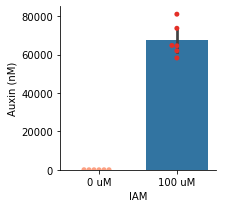

In [6]:

data = pd.io.excel.read_excel("Data_3a.xlsx")

fig = sns.FacetGrid(data=data,sharey=False)
fig = fig.map(sns.swarmplot,'Theo','Auxin (nM)',palette='Reds').add_legend()
fig = fig.map(sns.barplot,'Theo','Auxin (nM)').add_legend()
fig.savefig('Fig3A.svg')

print(np.mean(data[(data['Theo']=='0 mM')]['Auxin (nM)']))
print(np.mean(data[(data['Theo']=='1 mM')]['Auxin (nM)']))
print("Fold change:"+str((np.mean(data[(data['Theo']=='1 mM')]['Auxin (nM)']))/(np.mean(data[(data['Theo']=='0 mM')]['Auxin (nM)']))))

data = pd.io.excel.read_excel("Data_3b.xlsx")

fig = sns.FacetGrid(data=data,sharey=False)
fig = fig.map(sns.swarmplot,'IAM','Auxin (nM)',palette='Reds').add_legend()
fig = fig.map(sns.barplot,'IAM','Auxin (nM)').add_legend()
fig.savefig('Fig3B.svg')

print(np.mean(data[(data['IAM']=='0 uM')]['Auxin (nM)']))
print(np.mean(data[(data['IAM']=='100 uM')]['Auxin (nM)']))
print("Fold change:"+str((np.mean(data[(data['IAM']=='100 uM')]['Auxin (nM)']))/(np.mean(data[(data['IAM']=='0 uM')]['Auxin (nM)']))))


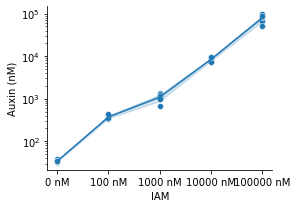

In [7]:

data = pd.io.excel.read_excel("Data_3c.xlsx")

fig = sns.FacetGrid(data=data,aspect=1.5)
fig = fig.map(sns.scatterplot,'IAM','Auxin (nM)')
fig = fig.map(sns.lineplot,'IAM','Auxin (nM)')
plt.yscale('log')
# plt.xscale('log')
fig.savefig('Fig3C.svg')


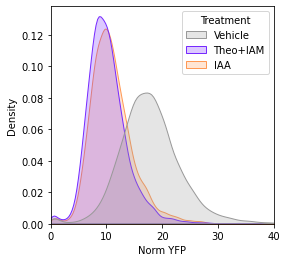

In [16]:
data_plot = pd.read_excel('Data_4b.xlsx')

custom_colors = {
    "Vehicle": "#99999940",   
    "Theo+IAM": "#772affff",  
    "IAA": "#ff9955ff"  
}


fig, ax = plt.subplots(figsize=(4, 4))
sns.kdeplot(
    data=data_plot,
    x="Norm YFP",
    fill=True, common_norm=False,hue="Treatment", palette=custom_colors)
plt.xlim(0,40)
fig.savefig('260926_Fig4B.svg')

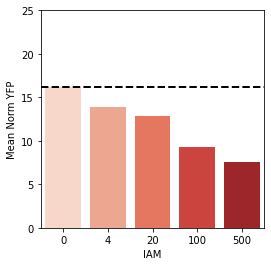

In [19]:
data_plot = pd.read_excel('Data_4c1.xlsx')

uninduced=16.181601929829583

fig, ax = plt.subplots(figsize=(4, 4))
sns.barplot(
    data=data_plot,
    y="Mean Norm YFP",
    x='IAM',palette='Reds')
plt.axhline(y=uninduced, color="black", linestyle="--", linewidth=2)
plt.ylim(0,25)
fig.savefig('260926_Fig4c1.svg')

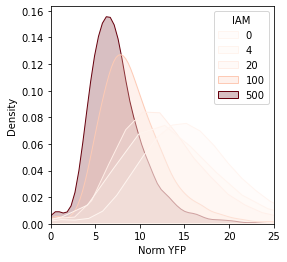

In [17]:
data_plot = pd.read_excel('Data_4c2.xlsx')

fig, ax = plt.subplots(figsize=(4, 4))
sns.kdeplot(
    data=data_plot,
    x="Norm YFP",
    fill=True, common_norm=False,hue="IAM",palette='Reds' )


plt.xlim(0,25)
fig.savefig('260926_Fig4c2.svg')


C:\Users\C837471923\AppData\Local\anaconda3\envs\flowcyto_env\lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


4.3902173042297346
5.743937969207765
3.9614701271057102
1.35372066497803
% difference (Leak IAM vs Theo): -23.567814837748717
% difference (DR IAM vs Theo): 192.63571352587738


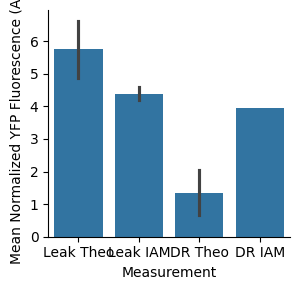

In [45]:
data = pd.io.excel.read_excel("Data_Sup5.xlsx")

fig = sns.FacetGrid(data=data,sharey=False)
#supernatant
fig = fig.map(sns.barplot,'Measurement','Mean Normalized YFP Fluorescence (AU)').add_legend()
#fig.savefig('SuppFig4C.svg')

print(np.mean(data[(data['Measurement']=='Leak IAM')]['Mean Normalized YFP Fluorescence (AU)']))
print(np.mean(data[(data['Measurement']=='Leak Theo')]['Mean Normalized YFP Fluorescence (AU)']))
print(np.mean(data[(data['Measurement']=='DR IAM')]['Mean Normalized YFP Fluorescence (AU)']))
print(np.mean(data[(data['Measurement']=='DR Theo')]['Mean Normalized YFP Fluorescence (AU)']))

print("% difference (Leak IAM vs Theo): " + str(
    ((np.mean(data[data['Measurement'] == 'Leak IAM']['Mean Normalized YFP Fluorescence (AU)']) -
      np.mean(data[data['Measurement'] == 'Leak Theo']['Mean Normalized YFP Fluorescence (AU)'])) /
      np.mean(data[data['Measurement'] == 'Leak Theo']['Mean Normalized YFP Fluorescence (AU)'])) * 100
))
print("% difference (DR IAM vs Theo): " + str(
    ((np.mean(data[data['Measurement'] == 'DR IAM']['Mean Normalized YFP Fluorescence (AU)']) -
      np.mean(data[data['Measurement'] == 'DR Theo']['Mean Normalized YFP Fluorescence (AU)'])) /
      np.mean(data[data['Measurement'] == 'DR Theo']['Mean Normalized YFP Fluorescence (AU)'])) * 100
))

#fig.savefig('SuppFig5.svg')

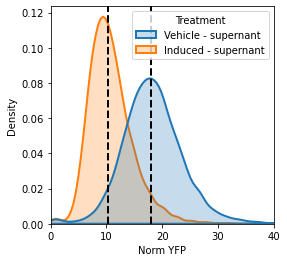

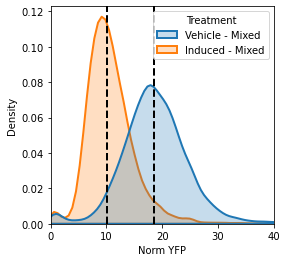

In [20]:
data_plot1 = pd.read_excel('Data_4d1.xlsx')
data_plot2 = pd.read_excel('Data_4d2.xlsx')

median1=18.03424644470215
median2=10.27404499053955
median3=18.484304428100586
median4=10.152953147888184

fig, ax = plt.subplots(figsize=(4, 4))
sns.kdeplot(
    data=data_plot1,
    x="Norm YFP",
    fill=True, common_norm=False,hue="Treatment",linewidth=2)
plt.axvline(x=median1, color="black", linestyle="--", linewidth=2)
plt.axvline(x=median2, color="black", linestyle="--", linewidth=2)
plt.xlim(0,40)
fig.savefig('260926_Fig4d1.svg')


fig, ax = plt.subplots(figsize=(4, 4))
sns.kdeplot(
    data=data_plot2,
    x="Norm YFP",
    fill=True, common_norm=False,hue="Treatment",linewidth=2)
plt.axvline(x=median3, color="black", linestyle="--", linewidth=2)
plt.axvline(x=median4, color="black", linestyle="--", linewidth=2)
plt.xlim(0,40)
fig.savefig('260926_Fig4d2.svg')

C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the swarmplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:675: UserWarning: Using the swarmplot function without specifying `hue_order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the boxplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


TL486
0.03349637778533007
0.041431227648219465
4.6234481072686393e-07


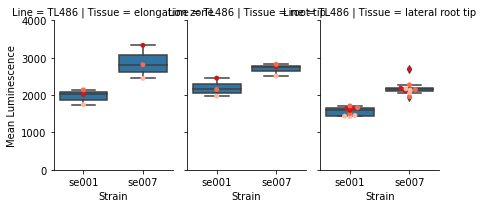

In [21]:
data = pd.io.excel.read_excel("Data_5A.xlsx")

fig = sns.FacetGrid(data=data,col='Tissue',row='Line',aspect=0.70)
fig = fig.map(sns.swarmplot,'Strain','Mean Luminescence','Replicate',palette='Reds')
fig = fig.map(sns.boxplot,'Strain','Mean Luminescence')
plt.ylim(0,4000)
fig.savefig('Fig5A.svg')


print("TL486")

t_stat, p_value = stats.ttest_ind(data[(data['Strain']=='se001')&(data['Line']=='TL486')&(data['Tissue']=='elongation zone')]['Mean Luminescence'], data[(data['Strain']=='se007')&(data['Line']=='TL486')&(data['Tissue']=='elongation zone')]['Mean Luminescence'])
print(p_value)

t_stat, p_value = stats.ttest_ind(data[(data['Strain']=='se001')&(data['Line']=='TL486')&(data['Tissue']=='root tip')]['Mean Luminescence'], data[(data['Strain']=='se007')&(data['Line']=='TL486')&(data['Tissue']=='root tip')]['Mean Luminescence'])
print(p_value)

t_stat, p_value = stats.ttest_ind(data[(data['Strain']=='se001')&(data['Line']=='TL486')&(data['Tissue']=='lateral root tip')]['Mean Luminescence'], data[(data['Strain']=='se007')&(data['Line']=='TL486')&(data['Tissue']=='lateral root tip')]['Mean Luminescence'])
print(p_value)



C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:337: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:670: UserWarning: Using the violinplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
C:\Users\khakhar\Anaconda3\lib\site-packages\seaborn\axisgrid.py:675: UserWarning: Using the violinplot function without specifying `hue_order` is likely to produce an incorrect plot.
  warnings.warn(warning)


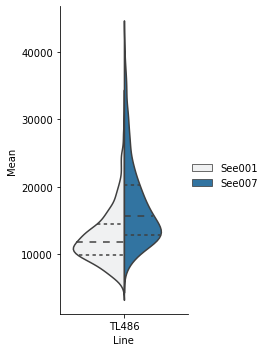

In [22]:
data_total= pd.io.excel.read_excel('Data_5B.xlsx')

fig = sns.FacetGrid(data=data_total,size=5,aspect=0.6)
fig = fig.map(sns.violinplot,'Line','Mean','Strain',split=True, inner='quart').add_legend()
fig.savefig('Fig5B.svg')

